In [ ]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem.rdchem import BondType

INPUT_CSV = "samplingDHA1.csv"

# Scaffold CORE sin attachment point (sin *)
CORE = "CC1CCC2C(C)C(O)OC3OC4(C)CCC1C32OO4"

OUT_ETHERS = "samplingDHA1_ethers.csv"
OUT_NON_ETHERS = "samplingDHA1_non_ethers.csv"
OUT_INVALID = "samplingDHA1_invalid.csv"

df = pd.read_csv(INPUT_CSV)

# --- Detecta columna de SMILES del PRODUCTO ---
candidate_cols = [c for c in df.columns if c.lower() in ["smiles", "sampled_smiles", "mol", "structure"]]
if not candidate_cols:
    # fallback: usa columnas tipo object
    candidate_cols = [c for c in df.columns if df[c].dtype == object]

def looks_like_product_smiles(s):
    if not isinstance(s, str): 
        return False
    s = s.strip()
    if len(s) < 5:
        return False
    # productos finales normalmente NO tienen '*'
    if "*" in s:
        return False
    return any(ch in s for ch in ["C","N","O","c","n","o"])

smiles_col = None
best_score = -1
for c in candidate_cols:
    sample = df[c].dropna().astype(str).head(50).tolist()
    score = sum(looks_like_product_smiles(x) for x in sample)
    if score > best_score:
        best_score = score
        smiles_col = c

if smiles_col is None or best_score <= 0:
    raise ValueError(f"No pude detectar una columna de SMILES de producto. Columnas: {list(df.columns)}")

print("Usando columna de producto:", smiles_col, " (score:", best_score, ")")

core = Chem.MolFromSmiles(CORE)
if core is None:
    raise ValueError("No pude parsear el CORE. Revisa el SMILES del core.")

core_query = Chem.MolFromSmarts(Chem.MolToSmarts(core)) ###convertir el core a SMARTS para que sea un query subestructural (ignora estereo, isotopos, etc)

def is_carbonyl_carbon(atom_c):
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE and b.GetOtherAtom(atom_c).GetSymbol() == "O":
            return True
    return False

def classify_ether_on_core(smiles):
    """
    Encuentra el core en la molécula final.
    Encuentra el oxígeno del core que tenga un vecino fuera del core (el O sustituido).
    Ether si ese vecino externo es C y no es carbonílico.
    """
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return "invalid"

    matches = m.GetSubstructMatches(core_query)
    if not matches:
        return "no_core"

    for match in matches:
        match_set = set(match)
        # busca O en el match que tenga vecino fuera del match (el sustituyente)
        for idx in match:
            a = m.GetAtomWithIdx(idx)
            if a.GetSymbol() != "O":
                continue
            outside = [n for n in a.GetNeighbors() if n.GetIdx() not in match_set]
            if len(outside) != 1:
                continue
            r_atom = outside[0]
            # Debe ser O–C
            if r_atom.GetSymbol() != "C":
                continue
            # No debe ser carbonilo: excluye O–C(=O)
            if is_carbonyl_carbon(r_atom):
                continue
            return "ether"

    return "non_ether"

df["class"] = df[smiles_col].astype(str).str.strip().map(classify_ether_on_core)

print(df["class"].value_counts())

ethers = df[df["class"] == "ether"].copy()
non_ethers = df[df["class"].isin(["non_ether", "no_core"])].copy()
invalid = df[df["class"] == "invalid"].copy()

ethers.to_csv(OUT_ETHERS, index=False)
non_ethers.to_csv(OUT_NON_ETHERS, index=False)
invalid.to_csv(OUT_INVALID, index=False)

print("\nSaved:")
print(" -", OUT_ETHERS, "rows:", len(ethers))
print(" -", OUT_NON_ETHERS, "rows:", len(non_ethers))
print(" -", OUT_INVALID, "rows:", len(invalid))

print("\nExample ethers:")
print(ethers[smiles_col].head(5).to_list())
print("\nExample non-ethers:")
print(non_ethers[smiles_col].head(5).to_list())

Usando columna de producto: SMILES  (score: 50 )
class
ether        221
non_ether    102
Name: count, dtype: int64

Saved:
 - samplingDHA1_ethers.csv rows: 221
 - samplingDHA1_non_ethers.csv rows: 102
 - samplingDHA1_invalid.csv rows: 0

Example ethers:
['COc1cc([N+](=O)[O-])c(OC)cc1COC1OC2OC3(C)CCC4C(C)CCC(C1C)C24OO3', 'CC1CCC2C(C)C(Oc3ccn(-c4c(F)c(F)c(F)c(F)c4F)c(=S)c3-c3ccc(OCc4ccccc4)cc3)OC3OC4(C)CCC1C32OO4', 'COc1cc(N)nc(NCCOC2OC3OC4(C)CCC5C(C)CCC(C2C)C35OO4)n1', 'CC1CCC2C(C)C(OCc3cc(F)c(F)c(F)c3F)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCCn3cnc4ncnc(NCc5c(F)cc(F)c(F)c5F)c43)OC3OC4(C)CCC1C32OO4']

Example non-ethers:
['Cc1cn(COCc2cccc3c2C=C3c2ccc([N+](=O)[O-])cc2)c(=O)c2c3c(c(CCCC(=O)OC4OC5OC6(C)CCC7C(C)CCC(C4C)C57OO6)c(C)c12)OCO3', 'CC1CCC2C(C)C(OC(=O)Cc3ccc(F)c(Cl)c3)OC3OC4(C)CCC1C32OO4', 'CC(=O)OCCc1cc(OCCNC(=O)OC2OC3OC4(C)CCC5C(C)CCC(C2C)C35OO4)cc2oc(=O)c(-c3ccc(O)cc3)c(-c3ccc(F)cc3)c12', 'CC1CCC2C(C)C(OC(=O)c3ccc(N=N)cc3Oc3ccc(F)cc3F)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OC(=O)CCCN

In [2]:
# Cargar el archivo de ethers
ethers = pd.read_csv("samplingDHA1_ethers.csv")

# SMARTS: oxígeno unido a un carbono carbonílico (O-C(=O))
ocoo = Chem.MolFromSmarts("O[C](=O)")

def has_ester_like(m):
    return m is not None and m.HasSubstructMatch(ocoo)

ms = [Chem.MolFromSmiles(s) for s in ethers["SMILES"].astype(str)]
bad = [i for i,m in enumerate(ms) if has_ester_like(m)]

print("Ethers total:", len(ethers))
print("Con motivo O-C(=O) en alguna parte:", len(bad))
print("Ejemplos (si hay):", ethers.iloc[bad[:5]]["SMILES"].to_list())

Ethers total: 221
Con motivo O-C(=O) en alguna parte: 25
Ejemplos (si hay): ['CC1CCC2C(C)C(OCC3CN(c4ccccc4)C(=O)O3)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCc3cc(C(=O)Nc4ccc(CC(=O)O)cc4)cc(Oc4ccc(F)c(F)c4)c3O)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCC(=O)OCCCNc3nccc(-c4cnc5ccccc5n4)n3)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCCOC(=O)c3cc(OCc4ccccc4F)c(OCc4ccccc4)c4ccc5ccccc5c34)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCc3cccc(C(=O)OC(C#N)CCCCc4ccccc4)c3)OC3OC4(C)CCC1C32OO4']


In [3]:
from rdkit.Chem.rdchem import BondType

CORE = "CC1CCC2C(C)C(O)OC3OC4(C)CCC1C32OO4"
core = Chem.MolFromSmiles(CORE)
core_query = Chem.MolFromSmarts(Chem.MolToSmarts(core))

def is_carbonyl_carbon(atom_c):
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE and b.GetOtherAtom(atom_c).GetSymbol() == "O":
            return True
    return False

def core_link_is_ether(smiles):
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return False

    matches = m.GetSubstructMatches(core_query)
    if not matches:
        return False

    for match in matches:
        match_set = set(match)
        for idx in match:
            a = m.GetAtomWithIdx(idx)
            if a.GetSymbol() != "O":
                continue
            outside = [n for n in a.GetNeighbors() if n.GetIdx() not in match_set]
            if len(outside) != 1:
                continue
            r_atom = outside[0]
            if r_atom.GetSymbol() != "C":
                continue
            if is_carbonyl_carbon(r_atom):
                continue
            return True
    return False

# Chequea todos
fails = []
for i, smi in enumerate(ethers["SMILES"].astype(str)):
    if not core_link_is_ether(smi):
        fails.append(i)

print("Ethers total:", len(ethers))
print("Que NO pasan la verificación exacta:", len(fails))
print("Ejemplos fallidos:", ethers.iloc[fails[:5]]["SMILES"].to_list())

Ethers total: 221
Que NO pasan la verificación exacta: 0
Ejemplos fallidos: []


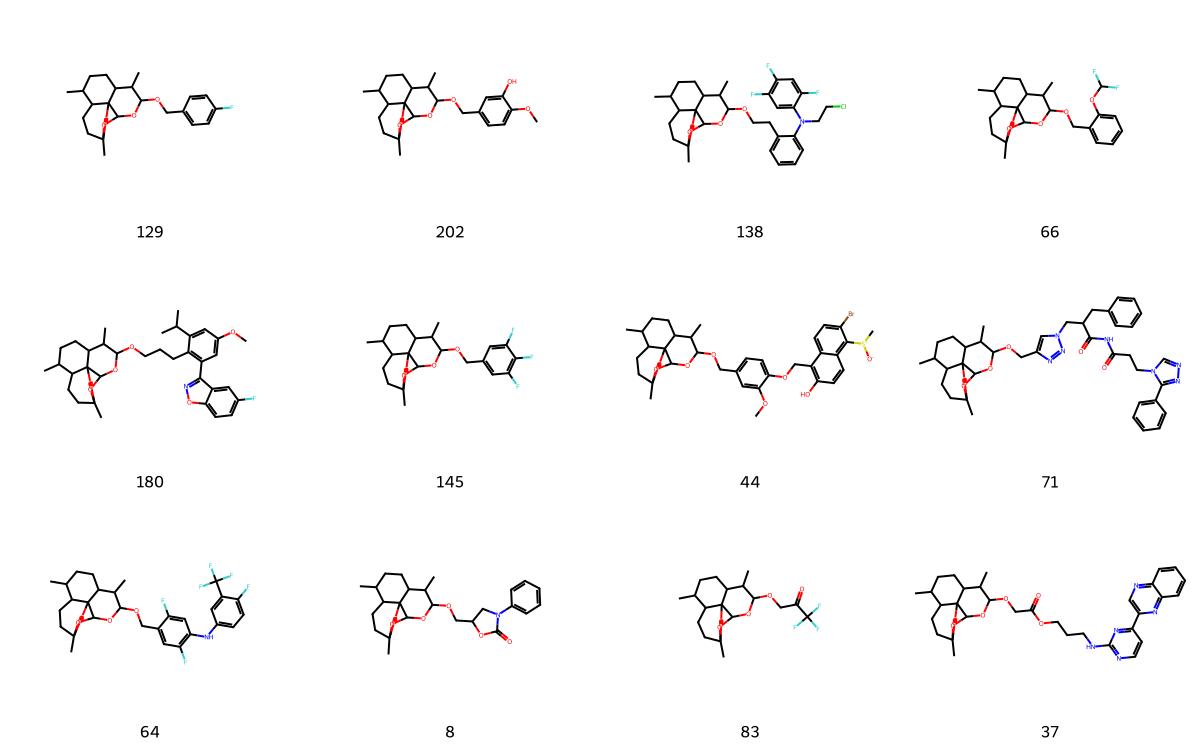

In [4]:
import random
from rdkit.Chem import Draw

sample = ethers.sample(n=min(12, len(ethers)), random_state=0)
mols = [Chem.MolFromSmiles(s) for s in sample["SMILES"].astype(str)]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 250), legends=[str(i) for i in sample.index])

In [5]:
from collections import Counter

# ============ PARTE 2: VALIDACIÓN DE ÉTER SIMPLE ============

ethers = pd.read_csv("samplingDHA1_ethers.csv")

smiles_col = next(
    (c for c in ethers.columns if c.lower() in ["smiles", "sampled_smiles", "mol"]),
    None
)
if smiles_col is None:
    raise ValueError(f"Columnas disponibles: {list(ethers.columns)}")

print(f"✓ Usando columna: {smiles_col}\n")

# Patrones SMARTS para éteres (alifáticos y aromáticos)
ether_aliphatic = Chem.MolFromSmarts("[CX4][OD2][CX4]")
ether_aromatic1 = Chem.MolFromSmarts("[cX3][OD2][CX4]")  # aromático-O-alifático
ether_aromatic2 = Chem.MolFromSmarts("[CX4][OD2][cX3]")  # alifático-O-aromático
ether_aromatic_both = Chem.MolFromSmarts("[cX3][OD2][cX3]")  # aromático-O-aromático

def is_true_ether(m):
    """
    Detecta éteres: alifáticos Y aromáticos
    Valida que tenga motivo R-O-R' donde R,R' pueden ser C o c
    """
    if m is None:
        return False
    
    return (m.HasSubstructMatch(ether_aliphatic) or
            m.HasSubstructMatch(ether_aromatic1) or
            m.HasSubstructMatch(ether_aromatic2) or
            m.HasSubstructMatch(ether_aromatic_both))

print("="*60)
print("PARTE 2: VALIDACIÓN DE ÉTER SIMPLE (R-O-R)")
print("="*60)

ms = []
invalid_indices = []

for i, s in enumerate(ethers[smiles_col].astype(str)):
    m = Chem.MolFromSmiles(s.strip())
    ms.append(m)
    if m is None:
        invalid_indices.append(i)

true_ethers_indices = []
false_ethers_indices = []

for i, m in enumerate(ms):
    if m is None:
        continue
    if is_true_ether(m):
        true_ethers_indices.append(i)
    else:
        false_ethers_indices.append(i)

print(f"\nResultados Parte 2:")
print(f"  Total compuestos: {len(ethers)}")
print(f"  SMILES inválidos: {len(invalid_indices)}")
print(f"  ✓ Verdaderos éteres (alifáticos + aromáticos): {len(true_ethers_indices)}")
print(f"  ✗ NO son éteres: {len(false_ethers_indices)}")

if false_ethers_indices:
    print(f"\nEjemplos de compuestos que NO tienen motivo éter:")
    for idx in false_ethers_indices[:3]:
        print(f"  {ethers.iloc[idx][smiles_col]}")

# Guardar después de Parte 2
ethers_part2 = ethers.iloc[true_ethers_indices].copy()
ethers_part2.to_csv("samplingDHA1_ethers_part2_validated.csv", index=False)

# ============ PARTE 3: VERIFICACIÓN DE ENLACE CORE ============

CORE = "CC1CCC2C(C)C(O)OC3OC4(C)CCC1C32OO4"
core = Chem.MolFromSmiles(CORE)
if core is None:
    raise ValueError("CORE SMILES inválido")

core_query = Chem.MolFromSmarts(Chem.MolToSmarts(core))

def is_carbonyl_carbon(atom_c):
    """Detecta C=O (carbonilo, no éter)"""
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE and b.GetOtherAtom(atom_c).GetSymbol() == "O":
            return True
    return False

def debug_core_link(smiles):
    """
    Verifica si el enlace O-sustituyente es un éter válido.
    Acepta C alifático y aromático (c).
    Retorna tipo de éter si es válido.
    """
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return "SMILES_INVALID"

    matches = m.GetSubstructMatches(core_query)
    if not matches:
        return "NO_CORE"

    for match in matches:
        match_set = set(match)
        oxygen_found = False
        
        for idx in match:
            a = m.GetAtomWithIdx(idx)
            if a.GetSymbol() != "O":
                continue
            
            oxygen_found = True
            outside = [n for n in a.GetNeighbors() if n.GetIdx() not in match_set]
            
            if len(outside) == 0:
                continue
            
            if len(outside) > 1:
                continue
            
            r_atom = outside[0]
            
            # Debe ser C (alifático o aromático)
            if r_atom.GetSymbol() != "C":
                return f"O_LINKED_TO_{r_atom.GetSymbol()}"
            
            # No debe ser carbonílico
            if is_carbonyl_carbon(r_atom):
                return "O_LINKED_TO_CARBONYL_C"
            
            # ✓ Es un éter válido - clasifica por tipo
            ether_type = "AROMATIC" if r_atom.GetIsAromatic() else "ALIPHATIC"
            return f"VALID_ETHER_{ether_type}"
    
    if not oxygen_found:
        return "NO_OXYGEN_IN_CORE"
    return "NO_OXYGEN_SUBSTITUTION"

def core_link_is_ether(smiles):
    """Versión simple para filtrar"""
    reason = debug_core_link(smiles)
    return reason.startswith("VALID_ETHER")

print("\n" + "="*60)
print("PARTE 3: VERIFICACIÓN DE ENLACE CORE-O-C")
print("="*60)

# Usar resultado de Parte 2
fail_reasons = {}
fails_idx = []

for i, smi in enumerate(ethers_part2[smiles_col].astype(str)):
    reason = debug_core_link(smi.strip())
    if not reason.startswith("VALID_ETHER"):
        fails_idx.append(i)
        fail_reasons[i] = reason

print(f"\nResultados Parte 3:")
print(f"  Total de Parte 2: {len(ethers_part2)}")
print(f"  ✓ Verificados correctamente: {len(ethers_part2) - len(fails_idx)}")
print(f"  ✗ Fallidos: {len(fails_idx)}")

# Desglose de ésteres por tipo
valid_reasons = {}
for i in range(len(ethers_part2)):
    if i not in fails_idx:
        reason = debug_core_link(ethers_part2.iloc[i][smiles_col].strip())
        valid_reasons[i] = reason

reason_counts = Counter(valid_reasons.values())
print(f"\nDesglose de éteres válidos por tipo:")
for reason, count in reason_counts.most_common():
    print(f"  - {reason}: {count}")

if fails_idx:
    fail_reason_counts = Counter(fail_reasons.values())
    print(f"\nDesglose de fallos:")
    for reason, count in fail_reason_counts.most_common():
        print(f"  - {reason}: {count}")

# Guardar resultados finales
valid_ethers_df = ethers_part2.iloc[
    [i for i in range(len(ethers_part2)) if i not in fails_idx]
].copy()

# Agregar columna de tipo de éter
valid_ethers_df['ether_type'] = [
    debug_core_link(smi.strip()).replace("VALID_ETHER_", "")
    for smi in valid_ethers_df[smiles_col].astype(str)
]

valid_ethers_df.to_csv("samplingDHA1_ethers_final.csv", index=False)

print(f"\n✓ Archivo guardado:")
print(f"  - samplingDHA1_ethers_final.csv ({len(valid_ethers_df)} filas)")
print(f"    → Alifáticos: {(valid_ethers_df['ether_type'] == 'ALIPHATIC').sum()}")
print(f"    → Aromáticos: {(valid_ethers_df['ether_type'] == 'AROMATIC').sum()}")

✓ Usando columna: SMILES

PARTE 2: VALIDACIÓN DE ÉTER SIMPLE (R-O-R)

Resultados Parte 2:
  Total compuestos: 221
  SMILES inválidos: 0
  ✓ Verdaderos éteres (alifáticos + aromáticos): 221
  ✗ NO son éteres: 0

PARTE 3: VERIFICACIÓN DE ENLACE CORE-O-C

Resultados Parte 3:
  Total de Parte 2: 221
  ✓ Verificados correctamente: 221
  ✗ Fallidos: 0

Desglose de éteres válidos por tipo:
  - VALID_ETHER_ALIPHATIC: 218
  - VALID_ETHER_AROMATIC: 3

✓ Archivo guardado:
  - samplingDHA1_ethers_final.csv (221 filas)
    → Alifáticos: 218
    → Aromáticos: 3


✓ Imagen guardada: samplingDHA1_ethers_aromatic_3.png


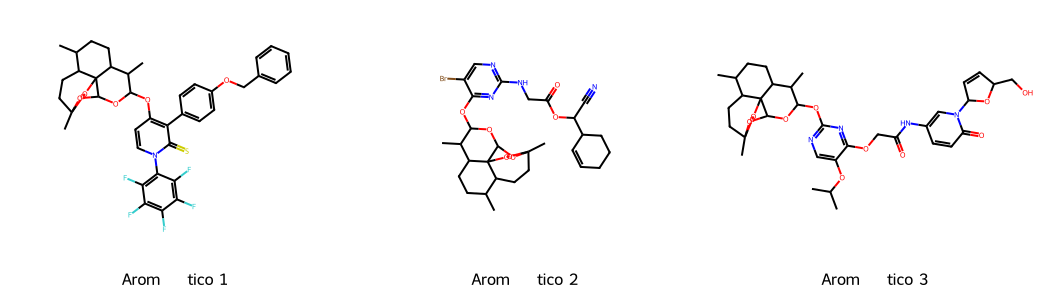

In [6]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw

ethers_final = pd.read_csv("samplingDHA1_ethers_final.csv")

smiles_col = next(
    (c for c in ethers_final.columns if c.lower() in ["smiles", "sampled_smiles", "mol"]),
    None
)

# Filtrar aromáticos
aromatic_ethers = ethers_final[ethers_final['ether_type'] == 'AROMATIC'].copy()

# Convertir a moléculas
mols = [Chem.MolFromSmiles(s.strip()) for s in aromatic_ethers[smiles_col].astype(str)]
mols = [m for m in mols if m is not None]

if mols:
    # Crear leyendas simples
    legends = [f"Aromático {i+1}" for i in range(len(mols))]
    
    # Graficar
    img = Draw.MolsToGridImage(
        mols,
        molsPerRow=3,
        subImgSize=(350, 300),
        legends=legends,
        returnPNG=False
    )
    
    img.save("samplingDHA1_ethers_aromatic_3.png", dpi=(150, 150))
    print(f"✓ Imagen guardada: samplingDHA1_ethers_aromatic_3.png")
    
    try:
        from IPython.display import display
        display(img)
    except ImportError:
        pass